# Problem set 7: Root-finding and interpolation - comments/solutions

# Programming for Economists Autumn 2026: Class 3
**Matias BF Hall**

A government has to raise tax revenue $G$. A higher tax rate $t$ takes a larger share of the tax base, but the base itself shrinks when taxes rise, for example because people work or declare less. In this problem set the base and revenue are

$$B(t)=100\,(1-t)^{1.5},\qquad R(t)=t\,B(t),\qquad 0\leq t\leq 1.$$

The question is simple: **which tax rate raises exactly $G=15$?** All numbers are illustrative (think of billions of DKK), not estimates for Denmark. The methods come from Lecture 7.

Each section repeats the inputs it needs. Solutions are in the files `A1.py`–`A6.py`; the cell after each task runs them. Try the task yourself before running that cell.

**Table of contents**<a id='toc0_'></a>    
- 1. [Revenue and the budget gap](#toc1_)    
- 2. [Bisection written as a function](#toc2_)    
- 3. [Two brackets, two answers](#toc3_)    
- 4. [Newton: the starting point decides](#toc4_)    
- 5. [A tax base known only from a table](#toc5_)    
- 6. [Optional: how much can the government raise?](#toc6_)    

<!-- vscode-jupyter-toc-config
	numbering=true
	anchor=true
	flat=false
	minLevel=2
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

## 1. <a id='toc1_'></a>[Revenue and the budget gap](#toc0_)

Write `tax_base(t)` and `revenue(t)`, and print revenue at $t=0.1$, $0.4$ and $0.7$. Then plot revenue for $t$ between 0 and 1 together with a horizontal line at $G=15$.

How many tax rates raise exactly 15? Finally, write `revenue_gap(t, G)`, which is zero at such a rate.

Revenue at t=0.1: 8.54
Revenue at t=0.4: 18.59
Revenue at t=0.7: 11.50


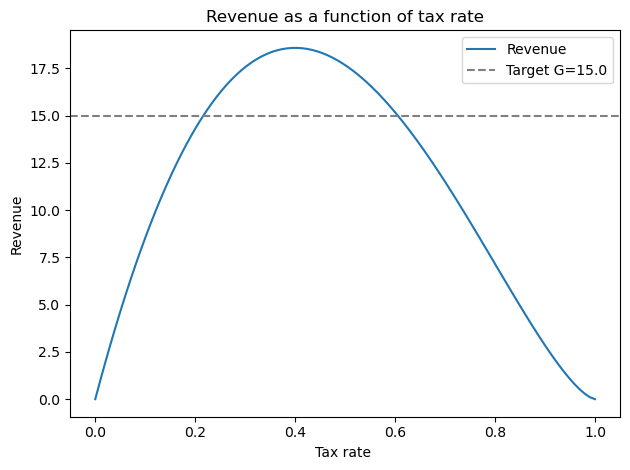

In [2]:
# define target, G
G = 15.0

# define functions
def tax_base(t):
    return 100*(1 - t)**1.5
def revenue(t):
    return t * tax_base(t)
def revenue_gap(t,G):
    return revenue(t) - G

for t in [0.1, 0.4, 0.7]:
    print(f"Revenue at t={t:.1f}: {revenue(t):.2f}")

# plot
t_values = np.linspace(0, 1, 100)
plt.plot(t_values, revenue(t_values), label='Revenue')
plt.axhline(G, color='gray', linestyle='--', label=f'Target G={G:.1f}')
plt.xlabel('Tax rate ')
plt.ylabel('Revenue')
plt.title('Revenue as a function of tax rate')
plt.legend()
plt.tight_layout()
plt.show()

# two tax rates hit the target revenue, one low and one high. We can find them using a root-finding algorithm.

## 2. <a id='toc2_'></a>[Bisection written as a function](#toc0_)

The loop in Lecture 7, Section 2 stops after exactly four halvings. Turn it into a function `bisection(f, a, b, tol)` that keeps halving **while** the bracket is wider than `tol`, and returns the midpoint together with the number of halvings. Raise an error if `f(a)` and `f(b)` have the same sign.

Use it on the bracket $[0, 0.4]$ with `tol = 1e-8`. Your `f` must take a single argument, so define `gap(t)` that returns `revenue_gap(t, 15)`.

In [3]:
def bisection(f, a, b, tol=1e-10, max_iter=500):
    """
    Bisection method for finding a root of f in [a,b]
    f: function for which we seek a root
    a,b: interval endpoints with f(a) and f(b) of opposite sign
    tol: tolerance for stopping criterion based on interval length
    max_iter: maximum number of iterations to prevent infinite loops
    returns: midpoint of final interval and number of iterations
    """
    
    # compute the function values and do checks
    fa, fb = f(a), f(b)
    # we check that we get a valid function value at the endpoints
    # we also check if either endpoint is exactly a root, that is we got the solution first try
    # lastly we check that the bisection algorithm can proceed
    if np.isnan(fa) or np.isnan(fb):
        raise ValueError("f(a) or f(b) is NaN.")
    if fa == 0.0: 
        return a, 0
    if fb == 0.0: 
        return b, 0
    if fa*fb > 0:
        raise ValueError("Bisection: root not bracketed. Choose f(a),f(b) with opposite signs.")
    # then we set the iteration counter and start the bisection loop
    # the loop runs until the interval is smaller than the tolerance or we reach the maximum number of iterations
    it = 0
    while (b - a) > tol and it < max_iter:
        # compute the halfway point and its function value
        m  = 0.5*(a + b)
        fm = f(m)
        # check if we found the root
        if fm == 0.0:
            a = b = m # sets both a and b to the midpoint, which is the root
            # break exits nearest enclosing loop, which is the if loop, not the while loop or the function call
            # the while loop will exit because b-a = 0 < tol
            break
        # if we did not find the root, update the interval
        if fa*fm < 0:
            b, fb = m, fm
        else:
            a, fa = m, fm
        # update the number of iterations    
        it += 1
    # return midpoint and number of iterations if either tolerance or max iterations are reached
    return 0.5*(a + b), it


# define gap function for root-finding
gap = lambda t: revenue_gap(t, G=15.0)
# use the bisection function
root1, it1 = bisection(gap, 0.0, 0.4, tol=1e-8)
# print the result
print(f'Tax rate: {root1:.4f}, Iterations: {it1}, Residual: {revenue_gap(root1, G=15.0):.8f}')


Tax rate: 0.2161, Iterations: 26, Residual: -0.00000006


## 3. <a id='toc3_'></a>[Two brackets, two answers](#toc0_)

For this tax base, revenue peaks at $t=1/(1+1.5)=0.4$ (take this as given). Use `optimize.root_scalar` with `method='brentq'` and `args=(G,)` on the brackets $[0, 0.4]$ and $[0.4, 1]$. Check `.converged` and the residual of each result.

Both rates raise the same revenue. Which one would a government choose, and why?

In [4]:
# define the two brackets
brackets = [(0.0, 0.4), (0.4, 1.0)]
# loop over the brackets and find the roots
for a, b in brackets:
    # solve
    sol = optimize.root_scalar(revenue_gap, args=(G,), method='brentq', bracket=[a, b])
    # print the results
    print(f'Bracket: [{a}, {b}], Tax rate: {sol.root:.4f}, Iterations: {sol.iterations}, Residual: {revenue_gap(sol.root, G=15.0):.2e}')

###### Which tax rate is preferred? #####
# Since most taxes are distotionary, the lower tax rate is likely to be preferred. 
# It brings in the same revenue with a smaller deadweight loss. 

Bracket: [0.0, 0.4], Tax rate: 0.2161, Iterations: 9, Residual: 0.00e+00
Bracket: [0.4, 1.0], Tax rate: 0.6056, Iterations: 9, Residual: -2.45e-12


## 4. <a id='toc4_'></a>[Newton: the starting point decides](#toc0_)

Newton needs the slope of revenue. Take it as given:

$$R'(t)=100\,(1-t)^{0.5}\,(1-2.5t).$$

Solve with `method='newton'`, `fprime=...` and `args=(G,)`, starting from $t=0.1$ and from $t=0.9$. Note that `root_scalar` passes `args` to the slope function too, so write it as `revenue_derivative(t, G)` even though it does not use `G`. Which root does each start find? What happens when you start at exactly $t=0.4$, and why? Look at the slope there.

In [5]:
# define the derivative of the revenue function
def revenue_prime(t, G):
    return 100*(1 - t)**0.5*(1 - 2.5*t)

# define a list of starting points
t_starts = [0.1, 0.4, 0.9]

# create a list to store the solutions, only needed if we want to save for later or use for plotting
solutions = []

# loop over the starting points and find the roots using Newton's method
for t0 in t_starts:
    # solve using Newton's method
    sol_newt = optimize.root_scalar(revenue_gap, fprime=revenue_prime, args=(G,), method='newton', x0=t0)
    # save the solution in the list
    solutions.append(sol_newt)
    # print the results
    print(f'Starting point: {t0:.1f}, Tax rate found: {sol_newt.root:.4f}, Solution found?: {sol_newt.converged}')

##### What happens at exactly 0.4? #####
# At exactly 0.4, the revenue function reaches its maximum.
# The derivative of the revenue function is zero at this point, which means that the slope of the revenue function is flat.
# This means the root finder does not know which direction to go, and it will not converge to a solution.
# This is even though it is at the solution, but the root finder does not know that.

Starting point: 0.1, Tax rate found: 0.2161, Solution found?: True
Starting point: 0.4, Tax rate found: 0.4000, Solution found?: False
Starting point: 0.9, Tax rate found: 0.6056, Solution found?: True


c:\Users\matia\Anaconda3\Lib\site-packages\scipy\optimize\_root_scalar.py:327: RuntimeWarning: Derivative was zero.
  r, sol = methodc(f, x0, args=args, fprime=fprime, fprime2=None,


## 5. <a id='toc5_'></a>[A tax base known only from a table](#toc0_)

In practice the ministry does not know the formula for the tax base. It has estimates at six tax rates only:

In [6]:
t_known = np.array([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
base_known = np.array([100.0, 71.6, 46.5, 25.3, 8.9, 0.0])

Write `revenue_from_table(t)`, which multiplies $t$ by the **interpolated** base (`np.interp`). Solve for both tax rates that raise $G=15$ with `brentq` and the brackets from Section 3, and compare them with the rates from the formula.

The table rates differ from the formula rates in the third decimal. Is that solver error or approximation error? What would make the difference smaller?

In [7]:
# define revenue function using the table and interpolation
def revenue_from_table(t):
    return t*np.interp(t, t_known, base_known)

# define function for root-finding
def revenue_gap_from_table(t):
    return revenue_from_table(t) - G

# print header for comparison table
print(f'{"Bracket":12s} {"Table":>9s} {"Formula":>9s} {"Difference":>11s}')
# loop over the brackets and find the roots using both methods
for a, b in brackets:
    # solve with table interpolation
    sol_table = optimize.root_scalar(revenue_gap_from_table, method='brentq', bracket=[a, b])
    # solve using the formula
    sol_formula = optimize.root_scalar(revenue_gap, args=(G,), method='brentq', bracket=[a, b])
    # print the results
    print(f'{str([a, b]):12s} {sol_table.root:9.4f} {sol_formula.root:9.4f} {sol_table.root - sol_formula.root:11.4f}')

##### Is it solver or approximation error? #####
# The difference is likely due to approximation error from the table interpolation.
# If the approximation were perfect, the solver would find the same root as the formula. 
# The difference is small, but it is not zero, indicating that the table interpolation introduces some error.
# However the approximation is accurate to two decimal places, so perhaps if the interpolation was done with more accuracy in the table, the difference would be even smaller.
# A finer grid for the table interpolation would also likely reduce the difference between the two methods.

Bracket          Table   Formula  Difference
[0.0, 0.4]      0.2153    0.2161     -0.0009
[0.4, 1.0]      0.6073    0.6056      0.0017


## 6. <a id='toc6_'></a>[Optional: how much can the government raise?](#toc0_)

For the targets $G = 5, 10, 15, 18$ and $20$, find the **lowest** tax rate that raises $G$, using the bracket $[0, 0.4]$ and the formula-based revenue. Check for a sign change before calling the solver, and print a message when there is none. Plot the required rate against the target.

What goes wrong at $G=20$, and what does it mean economically?

G =        5: tax rate = 0.0544
G =       10: tax rate = 0.1214
G =       15: tax rate = 0.2161
G =       18: tax rate = 0.3235
G =       20: tax rate = no tax rate between (0.0, 0.4) raises this much


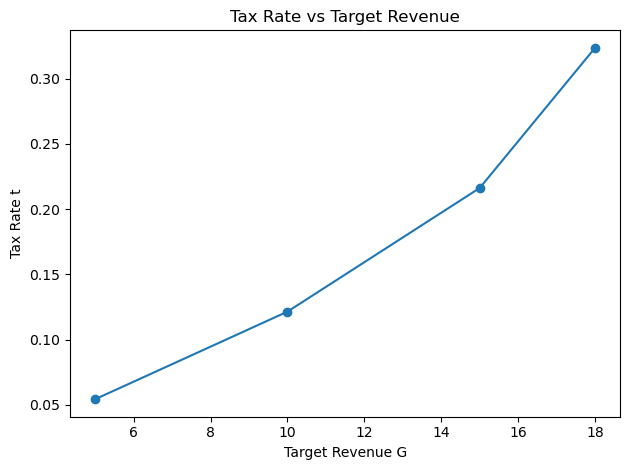

In [8]:
# tax targets to solve for
targets = [5.0, 10.0, 15.0, 18.0, 20.0]
# empty list to store the solutions
solutions = []

for target in targets:
    # try to solve for the target revenue using the formula and lower bracket. If the solver fails, print a message and continue to the next target.
    try:
        sol = optimize.root_scalar(revenue_gap, args=(target,), method='brentq', bracket=brackets[0])
    except: # except only runs if the try block fails
        print(f'G = {target:8.0f}: tax rate = no tax rate between {str(brackets[0])} raises this much')
        continue
    solutions.append(sol.root)
    print(f'G = {target:8.0f}: tax rate = {sol.root:.4f}')

# plot using saved solutions
plt.plot(targets[0:-1], solutions, marker='o')
plt.xlabel('Target Revenue G')
plt.ylabel('Tax Rate t')
plt.title('Tax Rate vs Target Revenue')
plt.tight_layout()
plt.show()

##### What goes wrong for G=20? #####
# For G=20, the solver fails because there is no tax rate between 0 and 0.4 that raises this much revenue.
# The Brentq method requires that the function values at the endpoints of the bracket have opposite signs, which is not the case for G=20.
# This is because the revenue minus 20 is always negative for tax rates between 0 and 0.4, so the solver cannot find a root in this interval.
# In this task we only check between 0 and 0.4, but we know that the maximum revenue is at t=0.4, so more generally we can say there is no tax rate that raises 20 units of revenue, because the maximum revenue is less than 20.